# Baseline: dual encoder (ResNet-18 + GRU)

This notebook is the **baseline solution** of the competition. It is the neural dual encoder from the lab:

* **image** → frozen ResNet-18 (ImageNet) feature map → small conv head → sum over positions → vector `i`;
* **caption** → word embeddings → bidirectional GRU → vector `t`;
* **score** = `sigmoid(scale · cos(i, t) + bias)`, the probability that the caption is TRUE, trained with binary cross-entropy.

At the end it writes **`submission.csv`**. The metric is ROC-AUC, so the submitted `label` is a score (higher = more likely TRUE),
not 0/1.

**How to run on Kaggle:** add the competition data to the notebook, turn on **GPU** and **Internet** (needed once to download the
ResNet-18 weights), then *Run all*. The whole notebook takes a few minutes on a GPU. The file appears in `/kaggle/working/`.
On Colab: upload the competition zip as `/content/competition_data.zip`.

## 1. Setup

In [1]:
import random, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from torchvision import transforms
from torchvision.models import resnet18, ResNet18_Weights
from sklearn.metrics import roc_auc_score

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
set_seed()

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cuda


## 2. Data

```
competition data/
├── train/  val/  test/     images (240 × 160 px)
├── train.csv, val.csv      id, image, caption, level, category, pair_id, label
├── test.csv                id, image, caption, level, category   (no label)
└── sample_submission.csv   id, label
```

In [2]:
kaggle_files = sorted(Path("/kaggle/input").glob("**/test.csv")) if Path("/kaggle/input").exists() else []
if kaggle_files:                                   # running on Kaggle
    DATA_DIR = kaggle_files[0].parent
    OUTPUT_DIR = Path("/kaggle/working")
else:                                              # running on Colab
    DATA_ZIP = Path("/content/competition_data.zip")
    DATA_DIR = Path("/content/contest")
    OUTPUT_DIR = Path("/content")
    if not DATA_DIR.exists():
        with zipfile.ZipFile(DATA_ZIP) as z:
            z.extractall(DATA_DIR)
    DATA_DIR = sorted(DATA_DIR.glob("**/test.csv"))[0].parent   # in case the zip has an extra top folder
print("data:", DATA_DIR)

train_df = pd.read_csv(DATA_DIR / "train.csv")
val_df = pd.read_csv(DATA_DIR / "val.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")
sample_submission = pd.read_csv(DATA_DIR / "sample_submission.csv")

# images are in the train/, val/ and test/ folders: keep the path relative to DATA_DIR
train_df["image"] = "train/" + train_df["image"]
val_df["image"] = "val/" + val_df["image"]
test_df["image"] = "test/" + test_df["image"]
test_df["label"] = 0          # unknown: a dummy value, only so that the same data loader works for test

print("rows   train:", len(train_df), "| val:", len(val_df), "| test:", len(test_df))
pd.DataFrame({"train": train_df["category"].value_counts(), "val": val_df["category"].value_counts(),
              "test": test_df["category"].value_counts()})

data: /kaggle/input/competitions/assessment-of-logical-statements-in-an-image-text-problem
rows   train: 29986 | val: 6000 | test: 35992


,train,val,test
category,,,
binding,5194,1054,6210
position,4786,960,5812
comparison,4618,904,5468
counting,4202,852,5072
negation,3630,700,4286
attribute,3066,584,3586
spatial,1706,354,1916
spatial_counting,1514,320,1912
spatial_negation,1270,272,1730


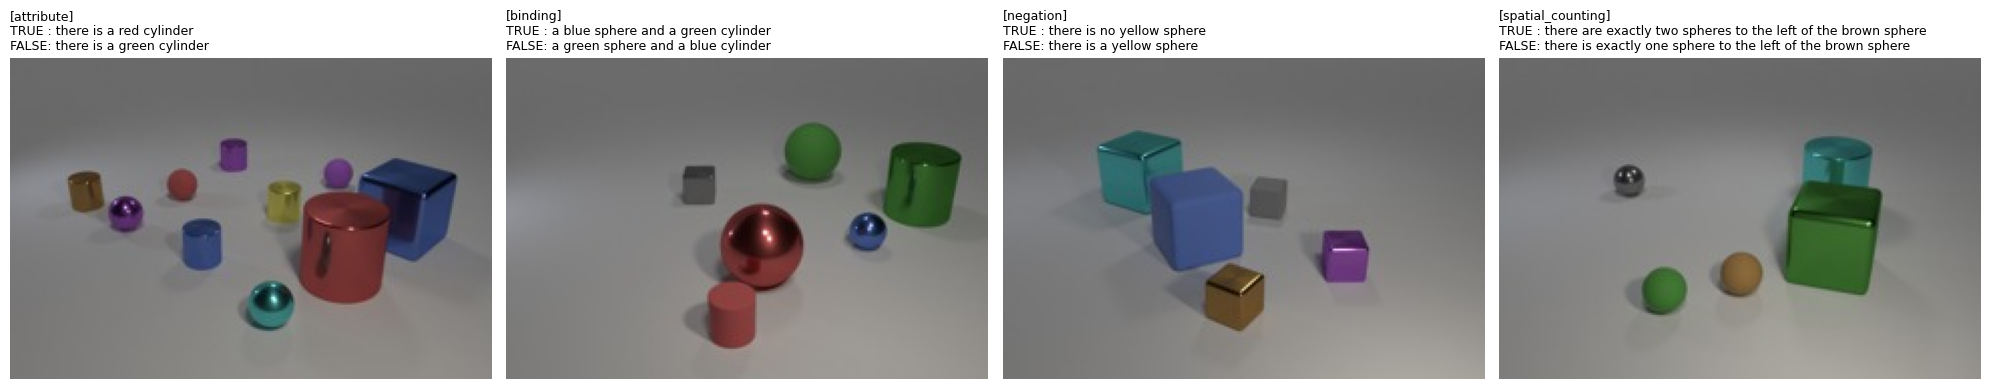

In [3]:
sample = train_df.drop_duplicates("pair_id").sample(4, random_state=0)
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, row in zip(axes, sample.itertuples()):
    pair = train_df[train_df["pair_id"] == row.pair_id].sort_values("label", ascending=False)
    ax.imshow(Image.open(DATA_DIR / row.image)); ax.axis("off")
    ax.set_title(f"[{row.category}]\nTRUE : {pair.iloc[0]['caption']}\nFALSE: {pair.iloc[1]['caption']}",
                 fontsize=9, loc="left")
plt.tight_layout(); plt.show()

## 3. Image features: frozen ResNet-18

The backbone is frozen, so we compute the feature maps **once** (512 channels × 5 × 8 positions per image) and train only
the small head on top. Every channel is standardised (mean 0, std 1).

In [4]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])
backbone = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
feature_extractor = nn.Sequential(*list(backbone.children())[:-2]).to(device).eval()   # drop avgpool + fc

all_images = sorted(set(train_df["image"]) | set(val_df["image"]) | set(test_df["image"]))
image_index = {name: i for i, name in enumerate(all_images)}

feature_maps = []
with torch.no_grad():
    for start in tqdm(range(0, len(all_images), 128), desc="ResNet-18 features"):
        batch = torch.stack([transform(Image.open(DATA_DIR / name).convert("RGB"))
                             for name in all_images[start:start + 128]]).to(device)
        feature_maps.append(feature_extractor(batch).half().cpu())
feature_maps = torch.cat(feature_maps).float()
channel_mean = feature_maps.mean(dim=(0, 2, 3), keepdim=True)
channel_std = feature_maps.std(dim=(0, 2, 3), keepdim=True) + 1e-6
feature_maps = ((feature_maps - channel_mean) / channel_std).half()   # float16 to save memory
print("feature maps:", tuple(feature_maps.shape))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 171MB/s]


ResNet-18 features:   0%|          | 0/94 [00:00<?, ?it/s]

feature maps: (12000, 512, 5, 8)


## 4. Text: tokens and vocabulary

In [5]:
def tokenize(caption):
    return caption.lower().split()

words = sorted({w for c in train_df["caption"] for w in tokenize(c)})
vocab = {"<pad>": 0, "<unk>": 1}
for w in words:
    vocab[w] = len(vocab)
MAX_LEN = max(len(tokenize(c)) for c in pd.concat([train_df["caption"], val_df["caption"], test_df["caption"]]))
print("vocabulary size:", len(vocab), "| longest caption:", MAX_LEN, "words")


def token_ids(captions):
    ids = np.zeros((len(captions), MAX_LEN), dtype=np.int64)
    lengths = np.zeros(len(captions), dtype=np.int64)
    for row, caption in enumerate(captions):
        toks = [vocab.get(w, 1) for w in tokenize(caption)]
        ids[row, :len(toks)] = toks
        lengths[row] = len(toks)
    return ids, lengths

vocabulary size: 57 | longest caption: 12 words


## 5. The dual encoder

```
feature map (512×5×8) ──► 1×1 conv ──► 3×3 conv ──► SUM over positions ──► linear ──► i (256) ─┐
                                                                                               ├─► scale · cos(i, t) + bias ──► sigmoid
caption tokens ──► embedding ──► bidirectional GRU ──► linear ──► t (256)                     ─┘
```

In [6]:
SUM_SCALE = 0.1   # sum over 40 positions gives large numbers; this keeps them in a comfortable range


class ImageEncoder(nn.Module):
    def __init__(self, out_dim=256, channels=128):
        super().__init__()
        self.conv = nn.Sequential(nn.Conv2d(512, channels, kernel_size=1), nn.ReLU(),
                                  nn.Conv2d(channels, channels, kernel_size=3, padding=1), nn.ReLU())
        self.fc = nn.Linear(channels, out_dim)

    def forward(self, maps):
        x = self.conv(maps)                       # (batch, channels, 5, 8)
        x = x.sum(dim=(2, 3)) * SUM_SCALE         # sum pooling over positions
        return self.fc(x)


class TextEncoder(nn.Module):
    def __init__(self, vocab_size, emb_dim=64, hidden=128, out_dim=256):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        self.gru = nn.GRU(emb_dim, hidden, batch_first=True, bidirectional=True)
        self.fc = nn.Linear(2 * hidden, out_dim)

    def forward(self, tokens, lengths):
        x = self.embedding(tokens)
        packed = nn.utils.rnn.pack_padded_sequence(x, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, h = self.gru(packed)                    # last state of each direction
        return self.fc(torch.cat([h[0], h[1]], dim=1))


class DualEncoder(nn.Module):
    def __init__(self, vocab_size, dim=256):
        super().__init__()
        self.image_encoder = ImageEncoder(dim)
        self.text_encoder = TextEncoder(vocab_size, out_dim=dim)
        self.log_scale = nn.Parameter(torch.tensor(np.log(10.0), dtype=torch.float32))
        self.bias = nn.Parameter(torch.zeros(1))

    def forward(self, maps, tokens, lengths):
        i = F.normalize(self.image_encoder(maps), dim=-1)
        t = F.normalize(self.text_encoder(tokens, lengths), dim=-1)
        return self.log_scale.exp() * (i * t).sum(dim=1) + self.bias     # one logit per pair

## 6. Training

We keep the weights from the epoch with the **best validation ROC-AUC** (the competition metric).
For the first epochs the loss often stays near 0.693 (= random guessing) before the model starts learning: be patient.

trainable parameters: 464706
epoch  1 | train loss 0.711 | val AUC 0.5002
epoch  2 | train loss 0.698 | val AUC 0.5000
epoch  3 | train loss 0.695 | val AUC 0.4983
epoch  4 | train loss 0.695 | val AUC 0.5033
epoch  5 | train loss 0.695 | val AUC 0.5071
epoch  6 | train loss 0.694 | val AUC 0.5036
epoch  7 | train loss 0.694 | val AUC 0.5016
epoch  8 | train loss 0.694 | val AUC 0.5105
epoch  9 | train loss 0.691 | val AUC 0.5270
epoch 10 | train loss 0.684 | val AUC 0.5573
epoch 11 | train loss 0.671 | val AUC 0.5530
epoch 12 | train loss 0.659 | val AUC 0.5638
epoch 13 | train loss 0.642 | val AUC 0.5731
epoch 14 | train loss 0.627 | val AUC 0.5713
epoch 15 | train loss 0.609 | val AUC 0.5780
epoch 16 | train loss 0.590 | val AUC 0.5782
epoch 17 | train loss 0.573 | val AUC 0.5714
epoch 18 | train loss 0.551 | val AUC 0.5721
epoch 19 | train loss 0.530 | val AUC 0.5797
epoch 20 | train loss 0.507 | val AUC 0.5681
epoch 21 | train loss 0.474 | val AUC 0.5813
epoch 22 | train loss 0.44

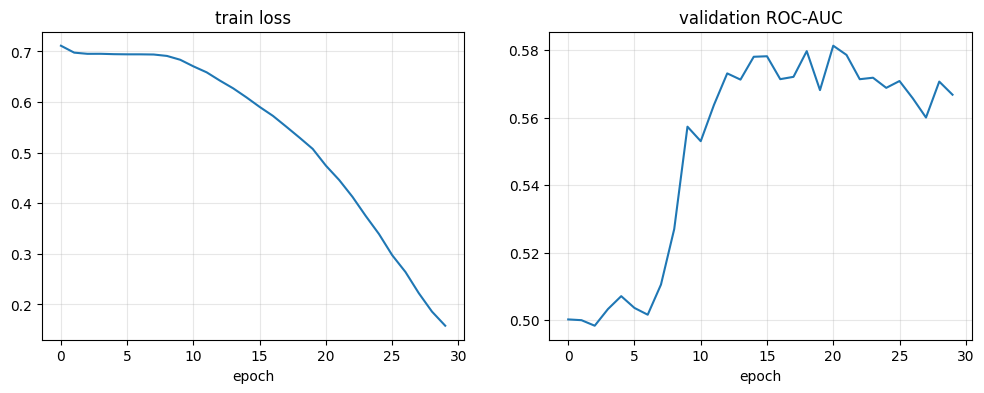

In [7]:
def make_loader(df, shuffle, batch_size=128):
    ids, lengths = token_ids(df["caption"].tolist())
    ds = TensorDataset(torch.tensor(df["image"].map(image_index).values), torch.tensor(ids),
                       torch.tensor(lengths), torch.tensor(df["label"].values, dtype=torch.float32))
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle,
                      generator=torch.Generator().manual_seed(SEED) if shuffle else None)


def forward_batch(model, batch):
    img_idx, tokens, lengths, labels = batch
    maps = feature_maps[img_idx].float().to(device)
    return model(maps, tokens.to(device), lengths), labels.to(device)


@torch.no_grad()
def predict(model, loader):
    model.eval()
    return torch.cat([torch.sigmoid(forward_batch(model, batch)[0]).cpu() for batch in loader]).numpy()


def train_model(model, train_df, val_df, epochs=30, lr=1e-3):
    model.to(device)
    train_loader, val_loader = make_loader(train_df, shuffle=True), make_loader(val_df, shuffle=False)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.BCEWithLogitsLoss()
    history = {"train_loss": [], "val_auc": []}
    best_auc, best_state = 0.0, None
    for epoch in range(epochs):
        model.train()
        total_loss, count = 0.0, 0
        for batch in train_loader:
            logits, labels = forward_batch(model, batch)
            loss = loss_fn(logits, labels)
            optimizer.zero_grad(); loss.backward(); optimizer.step()
            total_loss += loss.item() * len(labels); count += len(labels)
        val_auc = roc_auc_score(val_df["label"], predict(model, val_loader))
        history["train_loss"].append(total_loss / count); history["val_auc"].append(val_auc)
        if val_auc > best_auc:
            best_auc = val_auc
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        print(f"epoch {epoch + 1:2d} | train loss {history['train_loss'][-1]:.3f} | val AUC {val_auc:.4f}")
    model.load_state_dict(best_state)
    print(f"restored the weights with the best validation AUC ({best_auc:.4f})")
    return history


set_seed()
model = DualEncoder(len(vocab))
print("trainable parameters:", sum(p.numel() for p in model.parameters()))
history = train_model(model, train_df, val_df, epochs=30, lr=1e-3)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(history["train_loss"]); ax1.set_title("train loss")
ax2.plot(history["val_auc"]); ax2.set_title("validation ROC-AUC")
for ax in (ax1, ax2):
    ax.set_xlabel("epoch"); ax.grid(alpha=0.3)
plt.show()

## 7. Validation results per category

* **ROC-AUC**: the competition metric (0.5 = random, 1.0 = perfect).
* **Pair accuracy**: how often the TRUE caption scores higher than its FALSE twin for the same image (0.5 = random).

One overall number hides where the model fails, so look at the categories.

In [8]:
def pair_accuracy(df, scores):
    d = df.assign(score=scores)
    true_s = d[d["label"] == 1].set_index("pair_id")["score"]
    false_s = d[d["label"] == 0].set_index("pair_id")["score"]
    true_s, false_s = true_s.align(false_s, join="inner")
    return float(np.mean((true_s > false_s) + 0.5 * (true_s == false_s)))


val_scores = predict(model, make_loader(val_df, shuffle=False))
rows = [{"category": "ALL", "rows": len(val_df), "auc": roc_auc_score(val_df["label"], val_scores),
         "pair_acc": pair_accuracy(val_df, val_scores)}]
for category in sorted(val_df["category"].unique()):
    mask = (val_df["category"] == category).values
    rows.append({"category": category, "rows": int(mask.sum()),
                 "auc": roc_auc_score(val_df.loc[mask, "label"], val_scores[mask]),
                 "pair_acc": pair_accuracy(val_df[mask], val_scores[mask])})
pd.DataFrame(rows).round(3)

,category,rows,auc,pair_acc
0,ALL,6000,0.581,0.568
1,attribute,584,0.593,0.586
2,binding,1054,0.579,0.575
3,comparison,904,0.681,0.648
4,counting,852,0.549,0.556
5,negation,700,0.599,0.583
6,position,960,0.556,0.567
7,spatial,354,0.487,0.497
8,spatial_counting,320,0.497,0.450
9,spatial_negation,272,0.488,0.463


## 8. Submission

One row per test `id`, in the order of `sample_submission.csv`; `label` = the probability that the caption is TRUE.

In [9]:
test_scores = predict(model, make_loader(test_df, shuffle=False))
submission = sample_submission[["id"]].merge(pd.DataFrame({"id": test_df["id"], "label": test_scores}),
                                             on="id", how="left")
assert len(submission) == len(sample_submission) and submission["label"].notna().all()

submission.to_csv(OUTPUT_DIR / "submission.csv", index=False)
print("saved:", OUTPUT_DIR / "submission.csv")
submission.head()

saved: /kaggle/working/submission.csv


,id,label
0,35986,0.430123
1,35987,0.374522
2,35988,0.872048
3,35989,0.495282
4,35990,0.461478


## Where to go from here

This baseline squeezes the whole image into **one vector before it sees the caption**, so it is weak on counting, positions
and relations. Look at the per-category table above, pick the weakest categories and think about what information
the model is missing there. The lab notebook has more ideas (fusion models, CLIP) and the competition page has general tips.